# Recorrido por los resultados del TFM

**Detección de regímenes de mercado con machine learning aplicada al asset allocation táctico: clustering, clasificación supervisada y backtesting**

Este notebook reproduce, en orden, las cuatro figuras principales de la memoria del TFM. No reimplementa el pipeline completo: carga los artefactos ya calculados por los scripts de `src/` (paneles de datos, predicciones, métricas de cartera) y, cuando no existe un artefacto guardado para la figura en cuestión (caso del análisis SHAP), recalcula únicamente lo estrictamente necesario a partir del modelo ya entrenado.

Orden de las figuras:

1. Evolución de los regímenes de mercado detectados (1995-2026).
2. Importancia de variables (SHAP) del clasificador de régimen.
3. R² y acierto direccional de la Capa 2 (predicción de factores) frente a referencias ingenuas.
4. Evolución del capital invertido: cartera core-satélite vs. S&P 500.

Puede ejecutarse de principio a fin con `Kernel → Restart & Run All`.

In [1]:
import os
from pathlib import Path


def _encontrar_raiz_repo(marcador: str = "pyproject.toml") -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo (necesario porque Jupyter arranca con cwd = notebooks/)."""
    directorio = Path.cwd()
    while not (directorio / marcador).exists():
        if directorio == directorio.parent:
            raise FileNotFoundError(f"No se encontró {marcador} subiendo desde {Path.cwd()}")
        directorio = directorio.parent
    return directorio


os.chdir(_encontrar_raiz_repo())
print(f"Directorio de trabajo: {Path.cwd()}")

Directorio de trabajo: /Users/inigoochoa/Documents/2. Github/tfm-regimen-factor-timing


In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

from config.series import RUTA_DATOS_PROCESADOS

RUTA_FIGURAS = "reports/figuras"
Path(RUTA_FIGURAS).mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 20)

# Paleta común para los 4 regímenes, reutilizada en las Figuras 1 y 2.
NOMBRES_REGIMEN = {
    0: "Expansión",
    1: "Expansión tardía / Endurecimiento",
    2: "Crisis aguda",
    3: "Recuperación",
}
COLOR_REGIMEN = {
    0: "#4C9A63",   # verde: expansión
    1: "#E8A33D",   # ámbar: endurecimiento
    2: "#C0392B",   # rojo: crisis aguda
    3: "#4E79C4",   # azul: recuperación
}

## Figura 1 — Regímenes de mercado detectados (1995-2026)

Fuente: `panel_mensual_con_regimen.csv`, salida de `src/regime/kmeans_regimen.py` (columna `regimen`, la etiqueta de k-means -- no `regimen_predicho`, que es la reproducción del Random Forest sobre esos mismos datos).

Se representa el S&P 500 en escala logarítmica con el fondo coloreado según el régimen vigente en cada mes, y se enmarcan los dos episodios de crisis aguda más severos del periodo (2008-09 y el shock COVID de 2020) para contrastar visualmente que el clustering los aísla como régimen propio.

In [3]:
panel_regimen = pd.read_csv(
    f"{RUTA_DATOS_PROCESADOS}/panel_mensual_con_regimen.csv", parse_dates=["fecha"]
).sort_values("fecha").reset_index(drop=True)

print(f"Periodo: {panel_regimen['fecha'].min().date()} a {panel_regimen['fecha'].max().date()} ({len(panel_regimen)} meses)")
panel_regimen["regimen"].map(NOMBRES_REGIMEN).value_counts()

Periodo: 1994-12-31 a 2026-07-31 (380 meses)


regimen
Expansión                            140
Expansión tardía / Endurecimiento    122
Recuperación                         107
Crisis aguda                          11
Name: count, dtype: int64

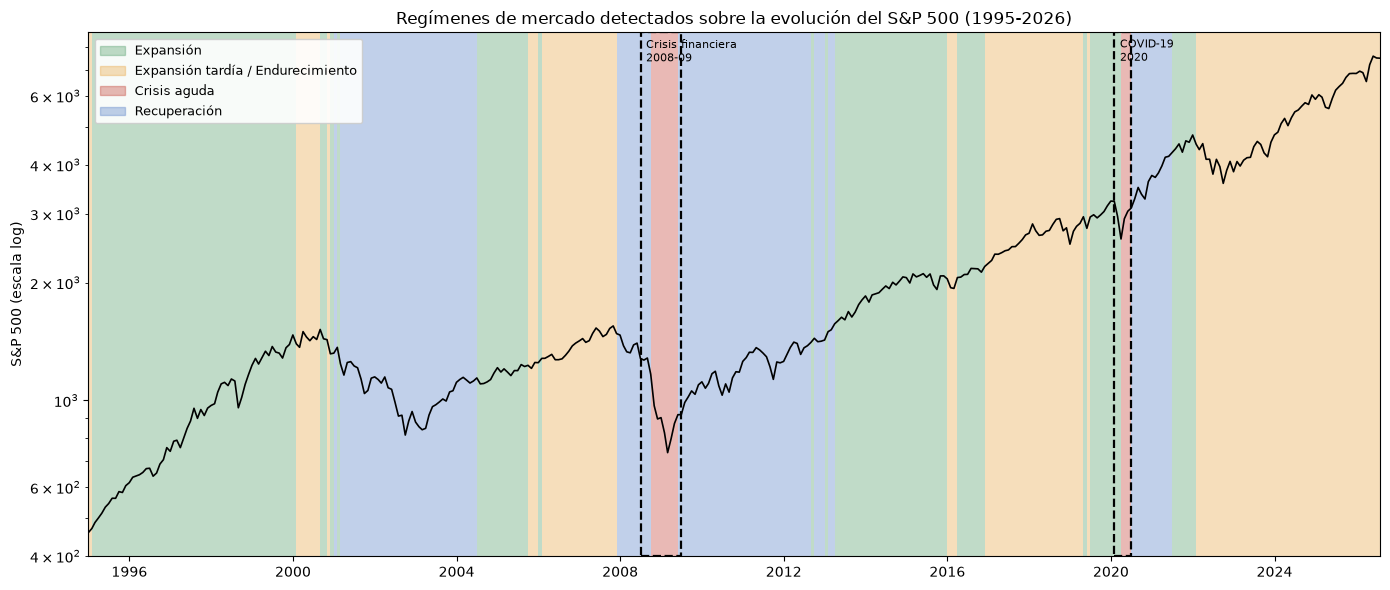

In [4]:
fig, ax = plt.subplots(figsize=(14, 6))

# Un axvspan por bloque contiguo de meses en el mismo régimen (no uno por mes).
regimenes = panel_regimen["regimen"].to_numpy()
cambio_bloque = np.r_[True, regimenes[1:] != regimenes[:-1]]
id_bloque = cambio_bloque.cumsum()

for _, bloque in panel_regimen.groupby(id_bloque):
    inicio = bloque["fecha"].iloc[0]
    idx_fin = bloque.index[-1]
    fin = panel_regimen["fecha"].iloc[min(idx_fin + 1, len(panel_regimen) - 1)]
    ax.axvspan(inicio, fin, color=COLOR_REGIMEN[bloque["regimen"].iloc[0]], alpha=0.35, lw=0)

ax.plot(panel_regimen["fecha"], panel_regimen["sp500"], color="black", lw=1.2)
ax.set_yscale("log")
ax.set_ylabel("S&P 500 (escala log)")
ax.set_title("Regímenes de mercado detectados sobre la evolución del S&P 500 (1995-2026)")

for inicio, fin, etiqueta in [
    ("2008-07-01", "2009-06-30", "Crisis financiera\n2008-09"),
    ("2020-02-01", "2020-06-30", "COVID-19\n2020"),
]:
    inicio_ts, fin_ts = pd.Timestamp(inicio), pd.Timestamp(fin)
    ax.axvspan(inicio_ts, fin_ts, fill=False, edgecolor="black", lw=1.6, linestyle="--")
    ax.annotate(
        etiqueta, xy=(inicio_ts, 1.0), xycoords=("data", "axes fraction"),
        xytext=(4, -4), textcoords="offset points", fontsize=8, ha="left", va="top",
    )

leyenda = [mpatches.Patch(color=COLOR_REGIMEN[k], alpha=0.35, label=v) for k, v in NOMBRES_REGIMEN.items()]
ax.legend(handles=leyenda, loc="upper left", fontsize=9, framealpha=0.9)
ax.set_xlim(panel_regimen["fecha"].min(), panel_regimen["fecha"].max())

plt.tight_layout()
plt.savefig(f"{RUTA_FIGURAS}/figura_1_regimenes_mercado.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 2 — Importancia de variables (SHAP) del clasificador de régimen

Fuente: `src/regime/rf_clasificador_regimen.py`. No existe un CSV guardado con el ranking agregado (el pipeline solo guarda los summary plots por régimen en `data/processed/shap_summary_*.png`), así que aquí se recalcula lo mínimo necesario: se reentrena el Random Forest con el mismo split temporal que usa el script (entrenamiento hasta 2019-12-31), se calculan los valores SHAP con `TreeExplainer` sobre el conjunto de entrenamiento, y se agregan en una única importancia global por variable (media del valor absoluto de SHAP entre las 4 clases de régimen).

El entrenamiento es rápido (500 árboles sobre ~300 observaciones, 19 features) -- del orden de unos segundos.

In [5]:
from regime.rf_clasificador_regimen import (
    entrenar_y_evaluar_rf_regimen,
    cargar_panel_con_regimen,
    preparar_datos_rf,
    dividir_train_test,
    calcular_valores_shap,
    resumen_importancia_global,
)

modelo_rf = entrenar_y_evaluar_rf_regimen()

Train: 301 obs (1994-12-31 a 2019-12-31)
Test:  79 obs (2020-01-31 a 2026-07-31)

Distribución de régimen en train:
regimen
0    131
1     67
2      8
3     95
Name: count, dtype: int64

Distribución de régimen en test:
regimen
0     9
1    55
2     3
3    12
Name: count, dtype: int64



=== F1 macro (test): 0.4728 ===

=== Classification report (test) ===
                                   precision    recall  f1-score   support

                        Expansión       0.22      0.56      0.31         9
Expansión tardía / Endurecimiento       1.00      0.67      0.80        55
                     Crisis aguda       0.00      0.00      0.00         3
                     Recuperación       0.63      1.00      0.77        12

                         accuracy                           0.68        79
                        macro avg       0.46      0.56      0.47        79
                     weighted avg       0.82      0.68      0.71        79

=== Matriz de confusión (filas=real, columnas=predicho) ===
                                   Expansión  Expansión tardía / Endurecimiento  Crisis aguda  Recuperación
Expansión                                  5                                  0             0             4
Expansión tardía / Endurecimiento         18      

In [6]:
panel_rf = cargar_panel_con_regimen()
datos_rf = preparar_datos_rf(panel_rf)
X_train, X_test, y_train, y_test = dividir_train_test(datos_rf)

valores_shap = calcular_valores_shap(modelo_rf, X_train)
importancia_shap = resumen_importancia_global(valores_shap, X_train)
importancia_shap

Train: 301 obs (1994-12-31 a 2019-12-31)
Test:  79 obs (2020-01-31 a 2026-07-31)

Distribución de régimen en train:
regimen
0    131
1     67
2      8
3     95
Name: count, dtype: int64

Distribución de régimen en test:
regimen
0     9
1    55
2     3
3    12
Name: count, dtype: int64


,feature,importancia_shap
0,tipo_2y_zscore_60m,0.061228
1,tasa_paro_zscore_60m,0.047765
2,tipo_10y_zscore_60m,0.045003
3,fed_funds_zscore_60m,0.044586
4,peticiones_paro,0.040514
5,spread_credito,0.039336
6,drawdown_sp500_12m,0.026487
7,indice_ciclo,0.021683
8,vix,0.017575
9,neutral,0.017277


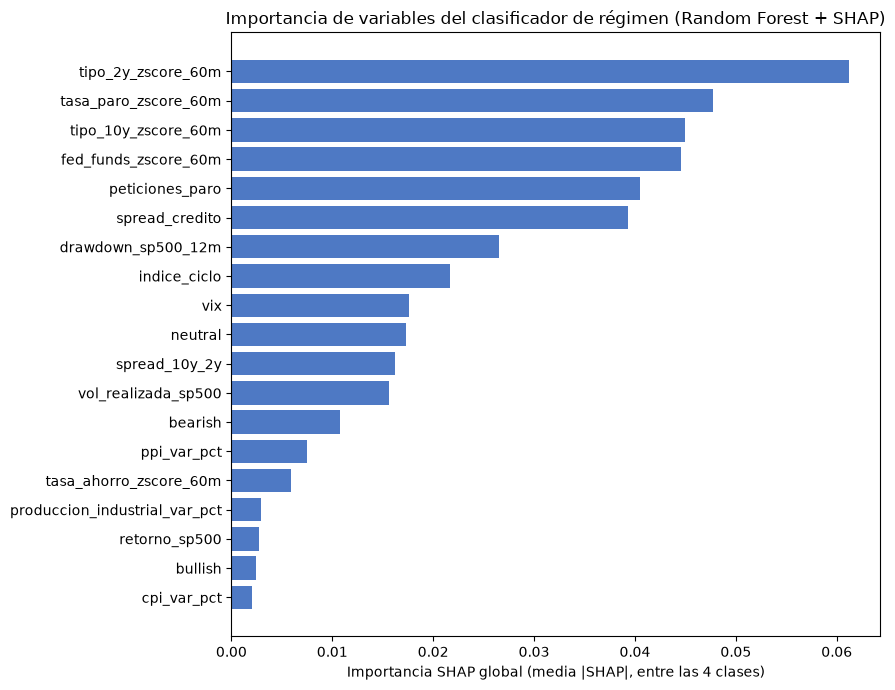

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))

orden = importancia_shap.sort_values("importancia_shap")
ax.barh(orden["feature"], orden["importancia_shap"], color="#4E79C4")
ax.set_xlabel("Importancia SHAP global (media |SHAP|, entre las 4 clases)")
ax.set_title("Importancia de variables del clasificador de régimen (Random Forest + SHAP)")

plt.tight_layout()
plt.savefig(f"{RUTA_FIGURAS}/figura_2_shap_importancia.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 3 — R² y acierto direccional por factor y horizonte (Capa 2 vs. referencias ingenuas)

Fuente: `data/processed/evaluacion_capa2_vs_baselines.csv`, generado por `src/factor_prediction/evaluacion_baseline.py`.

Se comparan tres modelos para cada uno de los 7 factores (Mkt-RF, SMB, HML, RMW, CMA, Mom, bab_usa) y 3 horizontes de predicción (corto, medio, largo):

- `rf_regularizado`: el modelo de Capa 2.
- `baseline_media_train`: predice siempre la media del factor en el periodo de entrenamiento.
- `baseline_cero`: predice siempre cero (sin acierto direccional definido -- predecir "cero" no toma partido por ninguna dirección).

In [8]:
evaluacion_capa2 = pd.read_csv(f"{RUTA_DATOS_PROCESADOS}/evaluacion_capa2_vs_baselines.csv")

ORDEN_HORIZONTE = ["corto", "medio", "largo"]
ORDEN_FACTOR = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom", "bab_usa"]
ORDEN_MODELO = ["rf_regularizado", "baseline_media_train", "baseline_cero"]
COLOR_MODELO = {"rf_regularizado": "#4E79C4", "baseline_media_train": "#E8A33D", "baseline_cero": "#A0A0A0"}

evaluacion_capa2.groupby(["horizonte", "modelo"])[["r2", "acierto_direccional"]].mean().round(4)

r2  acierto_direccional
horizonte modelo                                           
corto     baseline_cero        -0.0096                  NaN
          baseline_media_train -0.0097               0.5188
          rf_regularizado      -0.0050               0.4962
largo     baseline_cero        -0.1789                  NaN
          baseline_media_train -0.2004               0.5934
          rf_regularizado      -0.1361               0.5495
medio     baseline_cero        -0.0465                  NaN
          baseline_media_train -0.0265               0.5444
          rf_regularizado      -0.0191               0.5251

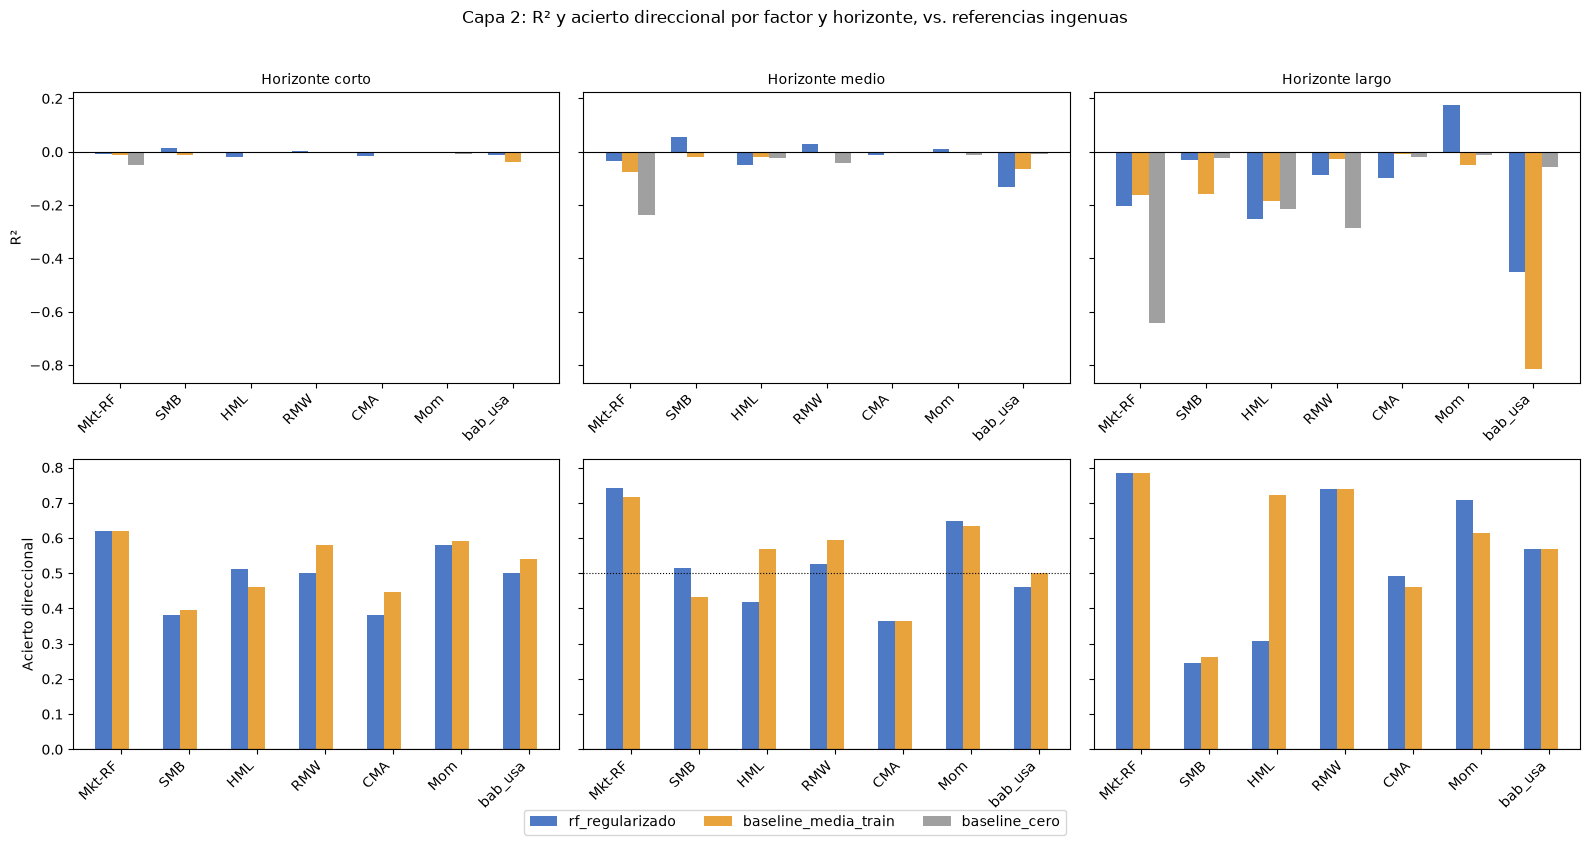

In [9]:
def graficar_metrica_agrupada(ax, horizonte, metrica, titulo, ylabel):
    ancho_barra = 0.25
    posiciones_factor = np.arange(len(ORDEN_FACTOR))
    datos_horizonte = evaluacion_capa2[evaluacion_capa2["horizonte"] == horizonte]

    for i, modelo in enumerate(ORDEN_MODELO):
        datos_modelo = datos_horizonte[datos_horizonte["modelo"] == modelo].set_index("factor")[metrica]
        valores = [datos_modelo.get(factor) for factor in ORDEN_FACTOR]
        ax.bar(
            posiciones_factor + (i - 1) * ancho_barra, valores, width=ancho_barra,
            label=modelo, color=COLOR_MODELO[modelo],
        )

    ax.set_xticks(posiciones_factor)
    ax.set_xticklabels(ORDEN_FACTOR, rotation=45, ha="right")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel(ylabel)


fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey="row")

for col, horizonte in enumerate(ORDEN_HORIZONTE):
    graficar_metrica_agrupada(axes[0, col], horizonte, "r2", f"Horizonte {horizonte}", "R²" if col == 0 else "")
    graficar_metrica_agrupada(axes[1, col], horizonte, "acierto_direccional", "", "Acierto direccional" if col == 0 else "")

axes[1, 1].axhline(0.5, color="black", lw=0.8, linestyle=":")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Capa 2: R² y acierto direccional por factor y horizonte, vs. referencias ingenuas", y=1.02)

plt.tight_layout()
plt.savefig(f"{RUTA_FIGURAS}/figura_3_capa2_vs_baselines.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 4 — Evolución del capital invertido: cartera core-satélite vs. S&P 500 (2014-2026)

Fuente: `data/processed/evolucion_capital_100k.csv`, generado por `src/portfolio/actualizar_evolucion_capital.py` a partir del motor de `src/portfolio/cartera_acciones.py`.

Tres series, todas partiendo de 100.000 (moneda base) en 2014-01-31: SPY puro, la cartera core-satélite con 5 puntos básicos de coste de transacción por operación, y la misma cartera sin fricción.

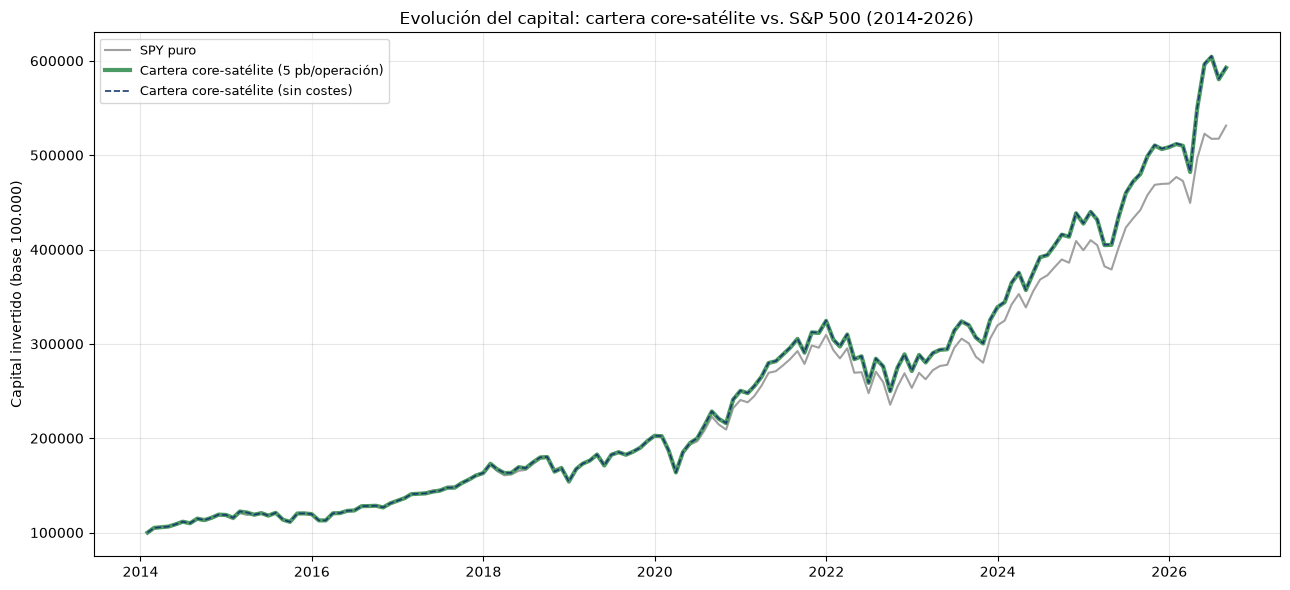

Capital final (2026-08-31):
  SPY puro:                          531,352
  Cartera core-satélite (sin costes): 593,337
  Cartera core-satélite (5 pb):       592,698


In [10]:
evolucion_capital = pd.read_csv(
    f"{RUTA_DATOS_PROCESADOS}/evolucion_capital_100k.csv", parse_dates=["fecha_mes"]
)

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(evolucion_capital["fecha_mes"], evolucion_capital["capital_spy"], label="SPY puro", color="#A0A0A0", lw=1.5, zorder=1)
ax.plot(evolucion_capital["fecha_mes"], evolucion_capital["capital_cartera_5pb"], label="Cartera core-satélite (5 pb/operación)", color="#4C9A63", lw=3, zorder=2)
ax.plot(evolucion_capital["fecha_mes"], evolucion_capital["capital_cartera_sin_costes"], label="Cartera core-satélite (sin costes)", color="#1B3B6F", lw=1.2, linestyle="--", zorder=3)

ax.set_ylabel("Capital invertido (base 100.000)")
ax.set_title("Evolución del capital: cartera core-satélite vs. S&P 500 (2014-2026)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{RUTA_FIGURAS}/figura_4_evolucion_capital.png", dpi=150, bbox_inches="tight")
plt.show()

capital_final = evolucion_capital.iloc[-1]
print(f"Capital final ({evolucion_capital['fecha_mes'].iloc[-1].date()}):")
print(f"  SPY puro:                          {capital_final['capital_spy']:,.0f}")
print(f"  Cartera core-satélite (sin costes): {capital_final['capital_cartera_sin_costes']:,.0f}")
print(f"  Cartera core-satélite (5 pb):       {capital_final['capital_cartera_5pb']:,.0f}")